# Example Notebook

In [1]:
import torch

use_cuda = torch.cuda.is_available()
device = torch.device('cuda' if use_cuda else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [2]:
import h5py
import numpy as np

In [3]:
# Define the path to one of your EMG-Pose files
file_path = "../data/2022-12-06-1670313600-e3096-cv-emg-pose-train@2-recording-9_right.hdf5"

with h5py.File(file_path, 'r') as f:
    # 'r' stands for read-only mode

    # This 'f' object is the HDF5 file (the root group)
    print(f"File Keys (Top-Level Groups/Datasets): {list(f.keys())}") 

    # You can now proceed to explore the structure
    # by iterating through the keys and accessing groups/datasets

File Keys (Top-Level Groups/Datasets): ['emg2pose']


In [4]:
def explore_h5_structure(h5_object, path='/'):
    # Iterate over all items in the current Group
    for key, item in h5_object.items():
        new_path = path + key + '/'
        
        # Check if the item is a Group (a folder)
        if isinstance(item, h5py.Group):
            print(f"GROUP: {new_path}")
            # Recursively explore the next level
            explore_h5_structure(item, new_path)
            
        # Check if the item is a Dataset (the data array)
        elif isinstance(item, h5py.Dataset):
            # Print important metadata for visualization/Dataset creation
            print(f"DATASET: {new_path.rstrip('/')}")
            print(f"  Shape: {item.shape}")
            print(f"  DType: {item.dtype}")
            # You can also print attributes (metadata) if they exist
            # print(f"  Attrs: {dict(item.attrs)}")

# Example of use:
with h5py.File(file_path, 'r') as f:
    explore_h5_structure(f)

GROUP: /emg2pose/
DATASET: /emg2pose/timeseries
  Shape: (121763,)
  DType: [('time', '<f8'), ('joint_angles', '<f4', (20,)), ('emg', '<f4', (16,))]


In [5]:

DATASET_PATH = '/emg2pose/timeseries'

with h5py.File(file_path, 'r') as f:
    # 1. Access the Dataset object
    ts_dataset = f[DATASET_PATH]
    
    # 2. Load the entire dataset (121763 rows) into memory.
    # The [:] or [()] slicing reads the data from disk into a NumPy array.
    structured_data = ts_dataset[:] 
    
print(f"Loaded Array Shape: {structured_data.shape}")
print(f"Data Fields: {structured_data.dtype.names}")

Loaded Array Shape: (121763,)
Data Fields: ('time', 'joint_angles', 'emg')


In [6]:
# 1. Extract the three main fields using field-name indexing
time_series = structured_data['time']
joint_angles = structured_data['joint_angles']
emg_signals = structured_data['emg']

# 2. Print the shapes to confirm
print(f"Time series shape: {time_series.shape}")     # (121763,) - 1D array of floats
print(f"Joint angles shape: {joint_angles.shape}")   # (121763, 20) - 2D array
print(f"EMG signals shape: {emg_signals.shape}")     # (121763, 16) - 2D array

Time series shape: (121763,)
Joint angles shape: (121763, 20)
EMG signals shape: (121763, 16)


In [7]:
emg_sample = emg_signals[1000:1100]

In [8]:
# Add parent directory to sys.path for imports
import sys
import os
parent_dir = os.path.abspath('..')

# 2. Insert the parent directory path at the beginning of sys.path
# Inserting at index 0 ensures it's checked before standard Python library paths.
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)
import src.utils.visualisation as vis

In [9]:
print(f"EMG Sample Shape: {emg_sample.shape}")  # Should be (100, 16)

EMG Sample Shape: (100, 16)


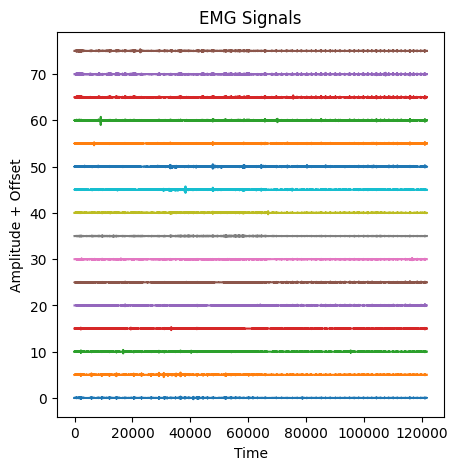

In [10]:
emg_sample = emg_signals[:]
emg_sample = emg_sample / np.max(np.abs(emg_sample))
vis.plot_emg(emg_sample.transpose())

In [11]:
import pandas as pd

# Load the metadata file
metadata_df = pd.read_csv('../data/metadata.csv')

# Convert relevant columns to appropriate types if needed
# For instance, the 'filename' will be the key for joining.
print(metadata_df.head())

                                           session        user  \
0  2022-04-07-1649318400-8125c-cv-emg-pose-train@2  29ddab35d7   
1  2022-04-07-1649318400-8125c-cv-emg-pose-train@2  29ddab35d7   
2  2022-04-07-1649318400-8125c-cv-emg-pose-train@2  29ddab35d7   
3  2022-04-07-1649318400-8125c-cv-emg-pose-train@2  29ddab35d7   
4  2022-04-07-1649318400-8125c-cv-emg-pose-train@2  29ddab35d7   

                              stage         start           end   side  \
0  ThumbsUpDownThumbRotationsCWCCWP  1.649400e+09  1.649400e+09   left   
1  ThumbsUpDownThumbRotationsCWCCWP  1.649400e+09  1.649400e+09  right   
2               HandClawGraspFlicks  1.649401e+09  1.649401e+09   left   
3               HandClawGraspFlicks  1.649401e+09  1.649401e+09  right   
4                  ShakaVulcanPeace  1.649401e+09  1.649401e+09   left   

                                            filename moving_hand  \
0  2022-04-07-1649318400-8125c-cv-emg-pose-train@...        both   
1  2022-04-07-16493184

In [12]:
metadata_df = metadata_df[metadata_df['split'] == "train"]
print(metadata_df.head())


                                               session        user  \
140  2022-04-12-1649750400-19a77-cv-emg-pose-demons...  4c4bfe28ea   
141  2022-04-12-1649750400-19a77-cv-emg-pose-demons...  4c4bfe28ea   
142  2022-04-12-1649750400-19a77-cv-emg-pose-demons...  4c4bfe28ea   
143  2022-04-12-1649750400-19a77-cv-emg-pose-demons...  4c4bfe28ea   
144  2022-04-12-1649750400-19a77-cv-emg-pose-demons...  4c4bfe28ea   

                  stage         start           end   side  \
140  TwoHandedFreeStyle  1.649750e+09  1.649750e+09   left   
141  TwoHandedFreeStyle  1.649750e+09  1.649750e+09  right   
142       unconstrained  1.649751e+09  1.649751e+09   left   
143   PokePinchCloseFar  1.649751e+09  1.649751e+09  right   
144  GraspPunchCloseFar  1.649751e+09  1.649751e+09   left   

                                              filename moving_hand  \
140  2022-04-12-1649750400-19a77-cv-emg-pose-demons...        both   
141  2022-04-12-1649750400-19a77-cv-emg-pose-demons...        both

In [18]:
file1 = metadata_df[metadata_df['filename'] == '2022-12-06-1670313600-b2eda-cv-emg-pose-demonstration@2-recording-6_left']

In [22]:
filename_groups = metadata_df.groupby('filename')
filename_counts = filename_groups.size()
print(filename_counts)

filename
2022-04-12-1649750400-19a77-cv-emg-pose-demonstration@2-recording-10_left     1
2022-04-12-1649750400-19a77-cv-emg-pose-demonstration@2-recording-10_right    1
2022-04-12-1649750400-19a77-cv-emg-pose-demonstration@2-recording-11_left     1
2022-04-12-1649750400-19a77-cv-emg-pose-demonstration@2-recording-11_right    1
2022-04-12-1649750400-19a77-cv-emg-pose-demonstration@2-recording-12_left     1
                                                                             ..
2022-12-06-1670313600-b2eda-cv-emg-pose-demonstration@2-recording-7_right     1
2022-12-06-1670313600-b2eda-cv-emg-pose-demonstration@2-recording-8_left      1
2022-12-06-1670313600-b2eda-cv-emg-pose-demonstration@2-recording-8_right     1
2022-12-06-1670313600-b2eda-cv-emg-pose-demonstration@2-recording-9_left      1
2022-12-06-1670313600-b2eda-cv-emg-pose-demonstration@2-recording-9_right     1
Length: 17136, dtype: int64


In [24]:
multi_stage_files = filename_counts[filename_counts > 1]
print(multi_stage_files)

Series([], dtype: int64)
